**Name: Akanksha Tiwari**
**Roll No. P26AI0002**

In [1]:
import numpy as np
from sklearn.datasets import fetch_olivetti_faces

#loading dataset
data = fetch_olivetti_faces()

X = data.images
y = data.target


#my roll number is p26ai0002, the numeric characters are 260002
rng = np.random.default_rng(260002)

train_idx = []
val_idx = []
test_idx = []

for person in range(40):
    idx = np.where(y == person)[0]
    idx = rng.permutation(idx) #randomly shuffling 10 images of the same identity

    #6 train, 2 val and 2 test
    train_idx.extend(idx[:6])
    val_idx.extend(idx[6:8])
    test_idx.extend(idx[8:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

np.savez(
    "split.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

In [2]:
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 240
Validation: 80
Test: 80


In [3]:

#creating the second test data
X_train = X[train_idx].reshape(len(train_idx), -1)
X_val = X[val_idx].reshape(len(val_idx), -1)
X_test = X[test_idx].reshape(len(test_idx), -1)

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

X_test_occ = X[test_idx].copy()
X_test_occ[:, 24:40, 24:40] = 0
X_test_occ = X_test_occ.reshape(len(test_idx), -1)

**Question 1: Decision tree baseline and bagging from scratch**

**Part (a)**

In [4]:
from sklearn.tree import DecisionTreeClassifier

In [5]:
depths = [2, 4, 8, 16, None]
leaves = [1, 2, 4]

tree_results = []

for d in depths:
    for l in leaves:
        tree = DecisionTreeClassifier(
            max_depth=d,
            min_samples_leaf=l,
            random_state=260002
        )

        tree.fit(X_train, y_train)

        train_acc = tree.score(X_train, y_train)
        val_acc = tree.score(X_val, y_val)

        tree_results.append([d, l, train_acc, val_acc])

        print(d, l, train_acc, val_acc)

2 1 0.075 0.05
2 2 0.075 0.05
2 4 0.075 0.05
4 1 0.125 0.1
4 2 0.125 0.1
4 4 0.125 0.1
8 1 0.225 0.1625
8 2 0.225 0.1625
8 4 0.225 0.1625
16 1 0.425 0.2875
16 2 0.425 0.2875
16 4 0.425 0.2875
None 1 1.0 0.5625
None 2 0.9916666666666667 0.625
None 4 0.9875 0.6


In [6]:
best_depth = None
best_leaf = 2

final_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=260002
)

final_tree.fit(X_train, y_train)

leaf_id = final_tree.apply(X_train)
_, counts = np.unique(leaf_id, return_counts=True)

print("Training accuracy:", final_tree.score(X_train, y_train))
print("Validation accuracy:", final_tree.score(X_val, y_val))
print("Test accuracy:", final_tree.score(X_test, y_test))
print("number of Leaves:", len(counts))
print("Mean samples per leaf:", counts.mean())
print("fraction of leaves containing only one training example:", np.mean(counts == 1))

Training accuracy: 0.9916666666666667
Validation accuracy: 0.625
Test accuracy: 0.6125
number of Leaves: 42
Mean samples per leaf: 5.714285714285714
fraction of leaves containing only one training example: 0.0


**Part (B)**

In [7]:
# implementing bagging by ourself
B_values = [1, 5, 10, 25, 50, 100, 200]
bootstrap_indices = []

rng_bag = np.random.default_rng(260002)

train_preds = []
val_preds = []
test_preds = []
distinct = []

n = len(X_train)

for i in range(200):

    idx = rng_bag.choice(n, n, replace=True)
    bootstrap_indices.append(idx)
    distinct.append(len(np.unique(idx)))

    tree = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=2,
        random_state=260002
    )

    tree.fit(X_train[idx], y_train[idx])

    train_preds.append(tree.predict(X_train))
    val_preds.append(tree.predict(X_val))
    test_preds.append(tree.predict(X_test))

In [8]:
#small voting function
def vote(preds):
    preds = np.array(preds)

    return np.array([
        np.bincount(preds[:, i], minlength=40).argmax()
        for i in range(preds.shape[1])
    ])

In [9]:
#presenting results
for B in B_values:

    p_train = vote(train_preds[:B])
    p_val = vote(val_preds[:B])
    p_test = vote(test_preds[:B])

    print(
        B,
        np.mean(p_train == y_train),
        np.mean(p_val == y_val),
        np.mean(p_test == y_test),
        np.mean(distinct[:B])
    )

1 0.7 0.475 0.3375 146.0
5 0.9541666666666667 0.6 0.4875 149.0
10 0.9958333333333333 0.7625 0.6125 148.5
25 1.0 0.75 0.725 149.88
50 1.0 0.8125 0.775 151.16
100 1.0 0.8375 0.8125 150.8
200 1.0 0.875 0.825 151.02


In [10]:
#comparing the expected value with theoritical expectation
expected = n * (1 - (1 - 1/n) ** n)
print("Expected distinct:", expected)
#last quantity settles around at the expected distinct as B becomes large

Expected distinct: 151.8931938460841


**Part (C)**

In [11]:
#computing the three required quantities

#out of bag accuracy calculation
def oob_acc(B):

    votes = [[] for _ in range(n)]

    for t in range(B):
        oob = np.setdiff1d(
            np.arange(n),
            np.unique(bootstrap_indices[t])
        )

        for i in oob:
            votes[i].append(train_preds[t][i])

    correct = []

    for i in range(n):
        if votes[i]:
            p = np.bincount(votes[i], minlength=40).argmax()
            correct.append(p == y_train[i])

    return np.mean(correct)

In [12]:
#pairwise disagreement calculation
def disagreement(B):

    if B == 1:
        return np.nan

    values = []

    for i in range(B):
        for j in range(i + 1, B):
            values.append(np.mean(val_preds[i] != val_preds[j]))

    return np.mean(values)

In [13]:
#vote margin calculation
def margin(B):

    preds = np.array(val_preds[:B])
    values = []

    for i in range(len(X_val)):
        count = np.sort(
            np.bincount(preds[:, i], minlength=40)
        )

        values.append((count[-1] - count[-2]) / B)

    return np.mean(values)

In [14]:
oob_scores = []
dis_scores = []
margin_scores = []

for B in B_values:

    oob_scores.append(oob_acc(B))
    dis_scores.append(disagreement(B))
    margin_scores.append(margin(B))

    print(
        B,
        oob_scores[-1],
        dis_scores[-1],
        margin_scores[-1]
    )

1 0.2978723404255319 nan 1.0
5 0.31981981981981983 0.79875 0.2425
10 0.42436974789915966 0.8125000000000001 0.2375
25 0.5666666666666667 0.8077916666666668 0.23600000000000004
50 0.7416666666666667 0.7898775510204081 0.271
100 0.7916666666666666 0.7992878787878788 0.26312499999999994
200 0.8416666666666667 0.7954855527638192 0.2729375


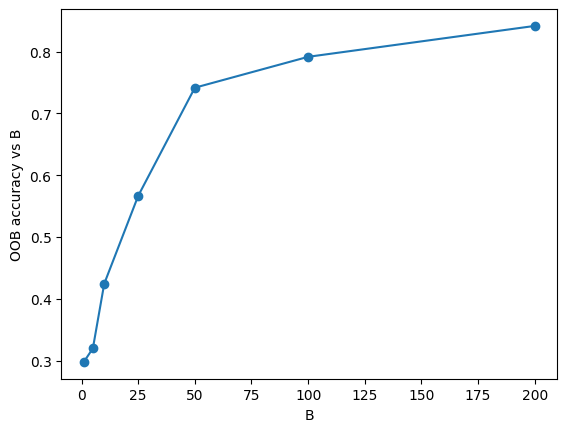

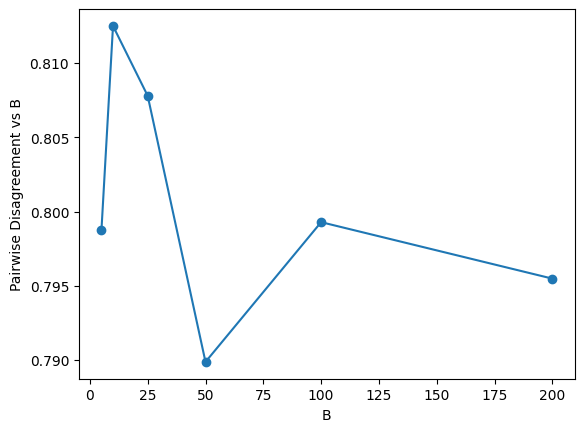

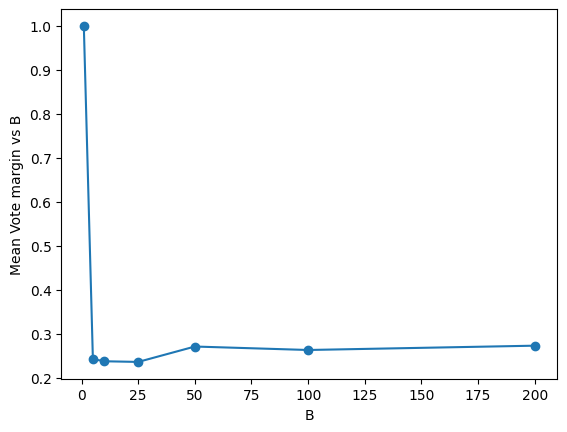

In [15]:
#plotting all three calculated values against B

import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

plt.figure()
plt.plot(B_values, oob_scores, 'o-')
plt.xlabel("B")
plt.ylabel("OOB accuracy vs B")
plt.savefig("figures/oob_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(B_values, dis_scores, 'o-')
plt.xlabel("B")
plt.ylabel("Pairwise Disagreement vs B")
plt.savefig("figures/disagreement.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(B_values, margin_scores, 'o-')
plt.xlabel("B")
plt.ylabel("Mean Vote margin vs B")
plt.savefig("figures/vote_margin.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
#calculating validation accuracy for each B
val_scores = []

for B in B_values:
    pred = vote(val_preds[:B])
    acc = np.mean(pred == y_val)

    val_scores.append(acc)

    print("B:", B, "Validation accuracy:", acc)

B: 1 Validation accuracy: 0.475
B: 5 Validation accuracy: 0.6
B: 10 Validation accuracy: 0.7625
B: 25 Validation accuracy: 0.75
B: 50 Validation accuracy: 0.8125
B: 100 Validation accuracy: 0.8375
B: 200 Validation accuracy: 0.875


In [17]:
#selecting the final ensemble size based on the best validation accuracy

final_B = B_values[np.argmax(val_scores)]

print("Final B:", final_B)

Final B: 200


**Part (D)**

In [18]:
#single tree predictions and confidence
tree_clean_pred = final_tree.predict(X_test)
tree_masked_pred = final_tree.predict(X_test_occ)

tree_clean_conf = final_tree.predict_proba(X_test).max(axis=1)
tree_masked_conf = final_tree.predict_proba(X_test_occ).max(axis=1)

In [19]:
#gettign masked predictions from 200 bagged trees

masked_preds = []

for i in range(final_B):

    idx = bootstrap_indices[i]

    tree = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=2,
        random_state=260002
    )

    tree.fit(X_train[idx], y_train[idx])
    masked_preds.append(tree.predict(X_test_occ))

In [20]:
#caluculating bagging predictions and confidence
bag_clean_pred = vote(test_preds[:final_B])
bag_masked_pred = vote(masked_preds)

def bag_confidence(preds):

    preds = np.array(preds)

    return np.array([
        np.bincount(preds[:, i], minlength=40).max() / len(preds)
        for i in range(preds.shape[1])
    ])

In [21]:
#printing the results

bag_clean_conf = bag_confidence(test_preds[:final_B])
bag_masked_conf = bag_confidence(masked_preds)
#first one shows accuracy and thge second oen shows mean confidence
print("Tree clean:", np.mean(tree_clean_pred == y_test), tree_clean_conf.mean())
print("Tree masked:", np.mean(tree_masked_pred == y_test), tree_masked_conf.mean())

print("Bagging clean:", np.mean(bag_clean_pred == y_test), bag_clean_conf.mean())
print("Bagging masked:", np.mean(bag_masked_pred == y_test), bag_masked_conf.mean())

Tree clean: 0.6125 0.9875
Tree masked: 0.075 1.0
Bagging clean: 0.825 0.3889375
Bagging masked: 0.7875 0.30262500000000003


In [22]:
#finding the example faces
corrected = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred == y_test)
)[0][:2]

both_wrong = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred != y_test)
)[0][:2]

print("Corrected:", corrected)
print("Both wrong:", both_wrong)

Corrected: [1 2]
Both wrong: [17 18]


In [23]:
#inspecting predictions and votecounts
examples = list(corrected) + list(both_wrong)

for i in examples:

    counts = np.bincount(
        np.array(test_preds[:final_B])[:, i],
        minlength=40
    )

    print("\nTrue:", y_test[i])
    print("Tree:", tree_clean_pred[i])
    print("Bagging:", bag_clean_pred[i])
    print("Votes:", [(j, counts[j]) for j in range(40) if counts[j] > 0])


True: 0
Tree: 36
Bagging: 0
Votes: [(0, 42), (1, 4), (2, 2), (3, 7), (4, 11), (5, 12), (8, 1), (9, 3), (11, 7), (12, 8), (14, 1), (15, 2), (16, 4), (17, 4), (21, 1), (22, 7), (25, 10), (27, 23), (28, 1), (33, 1), (34, 1), (36, 32), (37, 13), (39, 3)]

True: 1
Tree: 26
Bagging: 1
Votes: [(0, 3), (1, 99), (2, 1), (3, 16), (4, 4), (5, 2), (6, 2), (9, 4), (10, 1), (11, 4), (12, 6), (13, 3), (14, 7), (15, 9), (16, 4), (17, 1), (19, 3), (20, 3), (21, 2), (23, 4), (24, 1), (25, 1), (26, 7), (27, 1), (30, 2), (31, 2), (33, 3), (37, 2), (39, 3)]

True: 8
Tree: 12
Bagging: 14
Votes: [(0, 3), (1, 1), (2, 2), (3, 15), (4, 10), (6, 3), (7, 1), (8, 14), (9, 9), (10, 2), (11, 8), (12, 9), (13, 7), (14, 17), (15, 2), (16, 3), (17, 7), (18, 1), (19, 16), (20, 11), (22, 11), (23, 1), (24, 8), (25, 3), (26, 1), (27, 1), (28, 1), (29, 4), (30, 4), (31, 1), (32, 2), (34, 6), (37, 5), (39, 11)]

True: 9
Tree: 0
Bagging: 0
Votes: [(0, 28), (2, 7), (3, 10), (4, 5), (6, 2), (7, 1), (8, 5), (9, 12), (11, 3), (

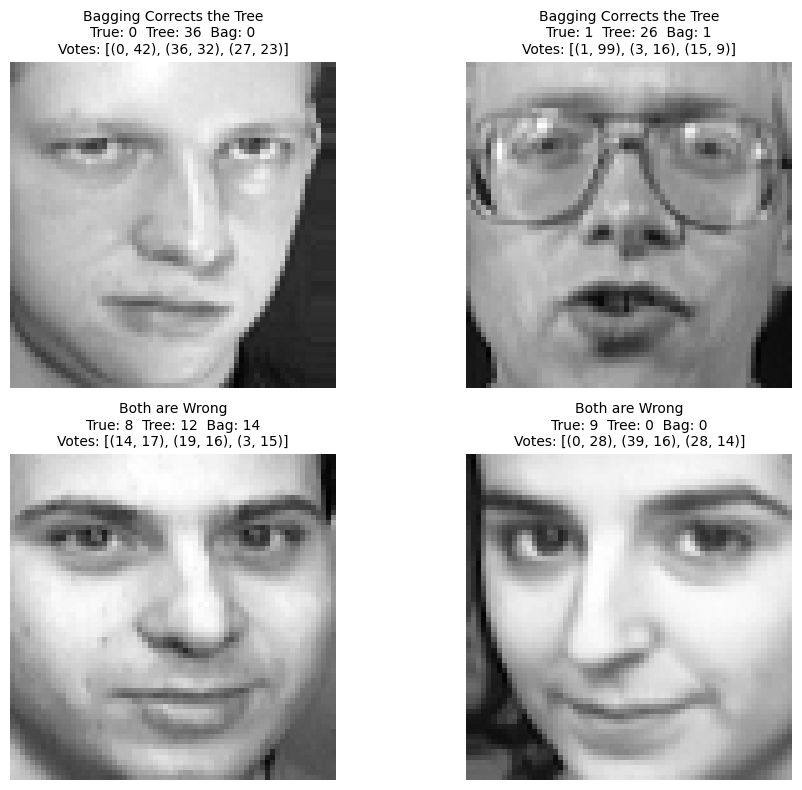

In [24]:
#printing and saving the face figures
examples = list(corrected) + list(both_wrong)

plt.figure(figsize=(10, 8))

for k, i in enumerate(examples):

    counts = np.bincount(
        np.array(test_preds[:final_B])[:, i],
        minlength=40
    )

    top = np.argsort(counts)[-3:][::-1]

    if k < 2:
        case = "Bagging Corrects the Tree"
    else:
        case = "Both are Wrong"

    plt.subplot(2, 2, k + 1)
    plt.imshow(X_test[i].reshape(64, 64), cmap="gray")
    plt.axis("off")

    plt.title(
        f"{case}\n"
        f"True: {y_test[i]}  Tree: {tree_clean_pred[i]}  Bag: {bag_clean_pred[i]}\n"
        f"Votes: {[(j, counts[j]) for j in top]}",
        fontsize=10
    )

plt.tight_layout()
plt.savefig("figures/error_cases.png", dpi=300, bbox_inches="tight")
plt.show()

**Question 2: Multiclass boosting from scratch**

**Part (A)**

In [25]:
#samme weight update
#increase the impoortance of misclassified samples so that the next weak learner focuses more on them.

X_small = np.array([[0], [1], [2], [3], [4], [5], [6], [7], [8]])
y_small = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

K = 3
w = np.ones(len(y_small)) / len(y_small)

tree = DecisionTreeClassifier(max_depth=1, random_state=260002)
tree.fit(X_small, y_small, sample_weight=w)

pred = tree.predict(X_small)
wrong = pred != y_small

error = np.sum(w[wrong])

print("Initial weights:", w)
print("Predictions:", pred)
print("Weighted error:", error)

if error >= 1 - 1/K:
    print("Weak learner not better than random")
else:
    alpha = np.log((1 - error) / error) + np.log(K - 1)

    w_new = w * np.exp(alpha * wrong)
    w_new = w_new / w_new.sum()

    print("Alpha:", alpha)
    print("Updated weights:", w_new)

Initial weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Predictions: [0 0 0 1 1 1 1 1 1]
Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908
Updated weights: [0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]


**Part (B)**

In [26]:
#samme training
def train_samme(X, y, depth, rounds):

    n = len(y)
    K = len(np.unique(y))
    w = np.ones(n) / n

    models = []
    alphas = []

    errors = []
    max_weights = []
    top10_weights = []

    for t in range(rounds):

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=260002
        )

        tree.fit(X, y, sample_weight=w)

        pred = tree.predict(X)
        wrong = pred != y

        error = np.sum(w[wrong])

        if error >= 1 - 1/K:
            break

        alpha = np.log((1 - error) / error) + np.log(K - 1)

        models.append(tree)
        alphas.append(alpha)
        errors.append(error)

        w = w * np.exp(alpha * wrong)
        w = w / w.sum()

        max_weights.append(w.max())
        top10_weights.append(np.sort(w)[-10:].sum())

    return models, np.array(alphas), errors, max_weights, top10_weights

In [27]:
#prediction function
def samme_predict(models, alphas, X):

    scores = np.zeros((len(X), 40))

    for tree, alpha in zip(models, alphas):

        pred = tree.predict(X)

        for i in range(len(X)):
            scores[i, pred[i]] += alpha

    return np.argmax(scores, axis=1)

In [28]:
#searching for the required configurations

depth_values = [1, 2, 3, 4]
round_values = [10, 25, 50, 100]

boost_results = []

for d in depth_values:

    models, alphas, errors, max_weights, top10_weights = train_samme(
        X_train, y_train, d, 100
    )

    for r in round_values:

        if len(models) >= r:

            pred = samme_predict(
                models[:r],
                alphas[:r],
                X_val
            )

            acc = np.mean(pred == y_val)

            boost_results.append((d, r, acc))

            print(d, r, acc)

1 10 0.05
1 25 0.0375
1 50 0.1
1 100 0.1125
2 10 0.0875
2 25 0.15
2 50 0.125
2 100 0.1
3 10 0.1625
3 25 0.125
3 50 0.2
3 100 0.2125
4 10 0.2125
4 25 0.2875
4 50 0.4375
4 100 0.525


In [29]:
#freezing the samme configuration
best_depth = 4
best_rounds = 100

boost_models, boost_alphas, boost_errors, boost_max_weights, boost_top10_weights = train_samme(
    X_train, y_train, best_depth, best_rounds
)

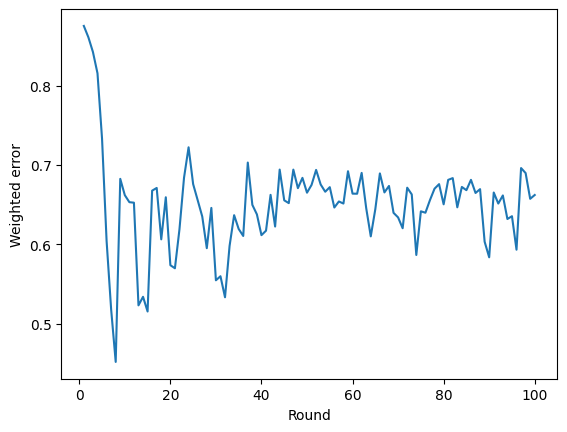

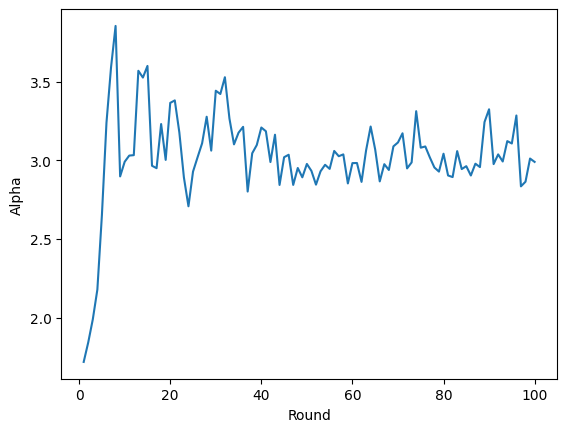

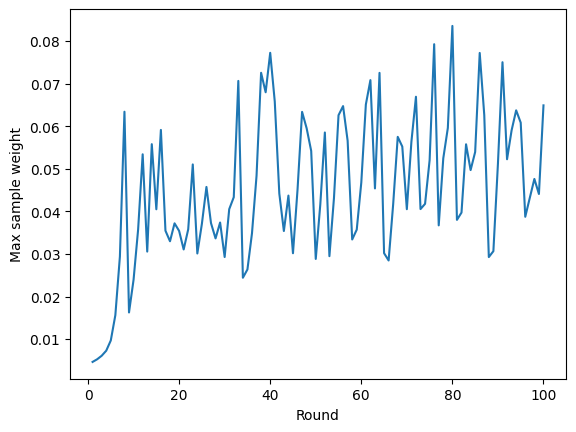

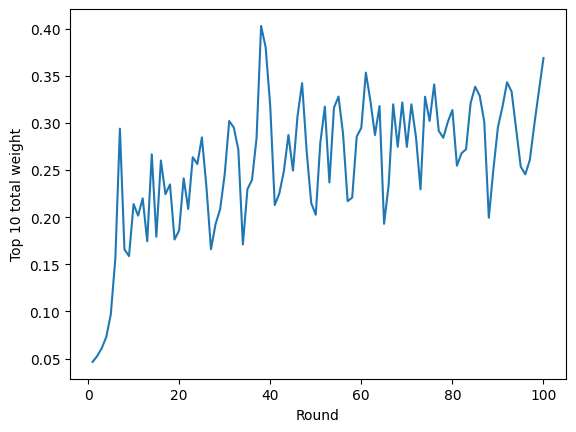

In [30]:
#saving the plots
r = np.arange(1, len(boost_alphas) + 1)

plt.figure()
plt.plot(r, boost_errors)
plt.xlabel("Round")
plt.ylabel("Weighted error")
plt.savefig("figures/samme_error.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(r, boost_alphas)
plt.xlabel("Round")
plt.ylabel("Alpha")
plt.savefig("figures/samme_alpha.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(r, boost_max_weights)
plt.xlabel("Round")
plt.ylabel("Max sample weight")
plt.savefig("figures/samme_max_weight.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(r, boost_top10_weights)
plt.xlabel("Round")
plt.ylabel("Top 10 total weight")
plt.savefig("figures/samme_top10_weight.png", dpi=300, bbox_inches="tight")
plt.show()

**Part (C)**

In [31]:
#bagging using 25, 50 and 100 learners
import time

compare_B = [25, 50, 100]

bag_train, bag_val, bag_test = [], [], []
bag_results = []

rng_compare = np.random.default_rng(260002)
bag_time = 0

for i in range(100):

    idx = rng_compare.choice(len(X_train), len(X_train), replace=True)

    tree = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=2,
        random_state=260002
    )

    t = time.perf_counter()
    tree.fit(X_train[idx], y_train[idx])
    bag_time += time.perf_counter() - t

    bag_train.append(tree.predict(X_train))
    bag_val.append(tree.predict(X_val))
    bag_test.append(tree.predict(X_test))

    B = i + 1

    if B in compare_B:
        bag_results.append([
            B,
            np.mean(vote(bag_train) == y_train),
            np.mean(vote(bag_val) == y_val),
            np.mean(vote(bag_test) == y_test),
            bag_time
        ])

In [32]:
#boosting using 25, 50 and 100 learners
boost_models_c = []
boost_alphas_c = []
boost_results_c = []

w = np.ones(len(X_train)) / len(X_train)
boost_time = 0

for i in range(100):

    tree = DecisionTreeClassifier(
        max_depth=4,
        random_state=260002
    )

    t = time.perf_counter()
    tree.fit(X_train, y_train, sample_weight=w)
    boost_time += time.perf_counter() - t

    pred = tree.predict(X_train)
    wrong = pred != y_train
    error = np.sum(w[wrong])

    if error >= 1 - 1/40:
        break

    alpha = np.log((1 - error) / error) + np.log(39)

    boost_models_c.append(tree)
    boost_alphas_c.append(alpha)

    w *= np.exp(alpha * wrong)
    w /= w.sum()

    B = i + 1

    if B in compare_B:

        a = np.array(boost_alphas_c)

        boost_results_c.append([
            B,
            np.mean(samme_predict(boost_models_c, a, X_train) == y_train),
            np.mean(samme_predict(boost_models_c, a, X_val) == y_val),
            np.mean(samme_predict(boost_models_c, a, X_test) == y_test),
            boost_time
        ])

In [33]:
#comparing the two results
#each row contains learners, train accuracy, validation accuracy, test accuracy and  training time
print("Bagging")
for x in bag_results:
    print(x)

print("\nBoosting")
for x in boost_results_c:
    print(x)

Bagging
[25, 1.0, 0.75, 0.725, 56.229760500000566]
[50, 1.0, 0.8125, 0.775, 112.93881990000045]
[100, 1.0, 0.8375, 0.8125, 224.3458926000003]

Boosting
[25, 0.5291666666666667, 0.2875, 0.275, 19.021398600000566]
[50, 0.975, 0.4375, 0.4375, 38.20162940000091]
[100, 1.0, 0.525, 0.475, 76.31874490000064]


In [34]:
#rerunning the selected boosting process, saving every samples' weight and prediction each round

w = np.ones(len(X_train)) / len(X_train)

weight_history = []
pred_history = []

for t in range(100):

    tree = DecisionTreeClassifier(
        max_depth=4,
        random_state=260002
    )

    tree.fit(X_train, y_train, sample_weight=w)

    pred = tree.predict(X_train)
    wrong = pred != y_train
    error = np.sum(w[wrong])

    if error >= 1 - 1/40:
        break

    alpha = np.log((1 - error) / error) + np.log(39)

    w *= np.exp(alpha * wrong)
    w /= w.sum()

    pred_history.append(pred.copy())
    weight_history.append(w.copy())

weight_history = np.array(weight_history)
pred_history = np.array(pred_history)

In [35]:
peak_round, hard_idx = np.unravel_index(
    np.argmax(weight_history),
    weight_history.shape
)

print("Index:", hard_idx)
print("True class:", y_train[hard_idx])
print("Max weight:", weight_history[peak_round, hard_idx])
print("Peak round:", peak_round + 1)

Index: 36
True class: 6
Max weight: 0.08354382694522319
Peak round: 80


In [36]:
#rounds where the face was misclassified
for t in range(len(pred_history)):

    if pred_history[t, hard_idx] != y_train[hard_idx]:

        print(
            t + 1,
            "pred:", pred_history[t, hard_idx],
            "weight:", weight_history[t, hard_idx]
        )

1 pred: 0 weight: 0.004642857142857143
3 pred: 2 weight: 0.0009647124030052967
4 pred: 3 weight: 0.0011535154432689469
5 pred: 4 weight: 0.0015340342280871877
6 pred: 12 weight: 0.0024747703649387618
7 pred: 14 weight: 0.0046578255543258396
8 pred: 13 weight: 0.010044833322444716
9 pred: 1 weight: 0.014349602398719115
10 pred: 3 weight: 0.02113449861173683
12 pred: 12 weight: 0.0022761552283228396
13 pred: 4 weight: 0.004240866926917149
14 pred: 14 weight: 0.007742047714525116
15 pred: 1 weight: 0.014640344718038035
16 pred: 3 weight: 0.0213789142582237
17 pred: 2 weight: 0.031061435720770397
19 pred: 12 weight: 0.002917383280271397
20 pred: 14 weight: 0.004956829808481837
21 pred: 20 weight: 0.00847913873333888
22 pred: 39 weight: 0.0133528161546452
23 pred: 3 weight: 0.019035947285837053
24 pred: 11 weight: 0.02569832703180103
25 pred: 38 weight: 0.03706945994424872
27 pred: 4 weight: 0.004131014557720576
28 pred: 14 weight: 0.006766325078004958
29 pred: 15 weight: 0.0102131157509003

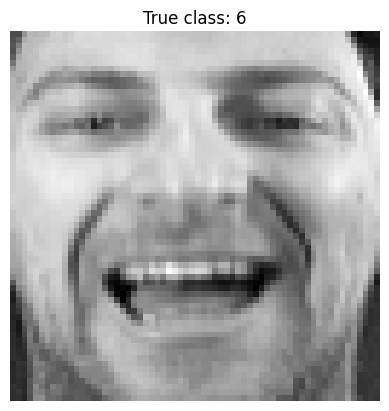

In [37]:
#saving the face
plt.figure()
plt.imshow(X_train[hard_idx].reshape(64, 64), cmap="gray")
plt.axis("off")
plt.title(f"True class: {y_train[hard_idx]}")

plt.savefig("figures/boosting_hard_face.png", dpi=300, bbox_inches="tight")
plt.show()

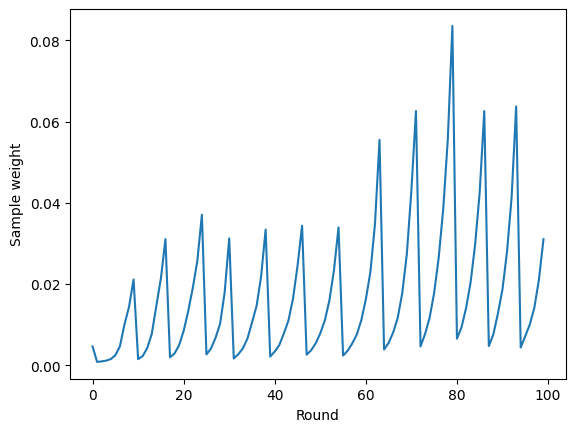

In [38]:
#saving the weight history
plt.figure()
plt.plot(weight_history[:, hard_idx])

plt.xlabel("Round")
plt.ylabel("Sample weight")

plt.savefig("figures/boosting_hard_face_weight.png", dpi=300, bbox_inches="tight")
plt.show()

**Part (D)**

In [39]:
#the frozen models are 

# Single tree:
# max_depth = None
# min_samples_leaf = 2

# Bagging:
# B = 200

# Boosting:
# depth = 4
# rounds = 100



In [40]:
#boosting prediction and confidence
def samme_predict_conf(models, alphas, X):

    scores = np.zeros((len(X), 40))

    for tree, alpha in zip(models, alphas):

        pred = tree.predict(X)

        for i in range(len(X)):
            scores[i, pred[i]] += alpha

    pred = np.argmax(scores, axis=1)
    conf = scores.max(axis=1) / np.sum(alphas)

    return pred, conf

In [41]:
#evaluate boosting
boost_clean_pred, boost_clean_conf = samme_predict_conf(
    boost_models, boost_alphas, X_test
)

boost_masked_pred, boost_masked_conf = samme_predict_conf(
    boost_models, boost_alphas, X_test_occ
)

In [42]:
#printing the results
print("Tree clean:", np.mean(tree_clean_pred == y_test), tree_clean_conf.mean())
print("Tree masked:", np.mean(tree_masked_pred == y_test), tree_masked_conf.mean())

print("Bagging clean:", np.mean(bag_clean_pred == y_test), bag_clean_conf.mean())
print("Bagging masked:", np.mean(bag_masked_pred == y_test), bag_masked_conf.mean())

print("Boosting clean:", np.mean(boost_clean_pred == y_test), boost_clean_conf.mean())
print("Boosting masked:", np.mean(boost_masked_pred == y_test), boost_masked_conf.mean())

Tree clean: 0.6125 0.9875
Tree masked: 0.075 1.0
Bagging clean: 0.825 0.3889375
Bagging masked: 0.7875 0.30262500000000003
Boosting clean: 0.475 0.11935770486924069
Boosting masked: 0.275 0.12996282257647696


In [43]:
#finding the face
diff_idx = np.where(
    (bag_masked_pred == y_test) &
    (boost_masked_pred != y_test)
)[0]

face_idx = diff_idx[0]

print("Index:", face_idx)
print("True:", y_test[face_idx])
print("Bag clean:", bag_clean_pred[face_idx])
print("Bag masked:", bag_masked_pred[face_idx])
print("Boost clean:", boost_clean_pred[face_idx])
print("Boost masked:", boost_masked_pred[face_idx])

Index: 2
True: 1
Bag clean: 1
Bag masked: 1
Boost clean: 14
Boost masked: 3


In [44]:
#inspecting bagging disagreement
bag_clean_votes = np.bincount(
    np.array(test_preds[:final_B])[:, face_idx],
    minlength=40
)

bag_masked_votes = np.bincount(
    np.array(masked_preds[:final_B])[:, face_idx],
    minlength=40
)

print("Bagging clean top votes:")
print(np.argsort(bag_clean_votes)[-3:][::-1],
      np.sort(bag_clean_votes)[-3:][::-1])

print("Bagging masked top votes:")
print(np.argsort(bag_masked_votes)[-3:][::-1],
      np.sort(bag_masked_votes)[-3:][::-1])

Bagging clean top votes:
[ 1  3 15] [99 16  9]
Bagging masked top votes:
[ 1 33 12] [74 14 14]


In [45]:
clean_disagreement = 1 - bag_clean_votes.max() / final_B
masked_disagreement = 1 - bag_masked_votes.max() / final_B

print("Clean disagreement:", clean_disagreement)
print("Masked disagreement:", masked_disagreement)
#higher value means the bagged trees disagree more

Clean disagreement: 0.505
Masked disagreement: 0.63


In [46]:
#inspecting boosting weiugheted votes
def boosting_scores(models, alphas, X):

    scores = np.zeros((len(X), 40))

    for tree, alpha in zip(models, alphas):
        pred = tree.predict(X)

        for i in range(len(X)):
            scores[i, pred[i]] += alpha

    return scores

In [47]:
boost_clean_scores = boosting_scores(
    boost_models, boost_alphas, X_test
)

boost_masked_scores = boosting_scores(
    boost_models, boost_alphas, X_test_occ
)

clean_top = np.argsort(boost_clean_scores[face_idx])[-3:][::-1]
masked_top = np.argsort(boost_masked_scores[face_idx])[-3:][::-1]

print("Boosting clean top:")
for c in clean_top:
    print(c, boost_clean_scores[face_idx, c])

print("Boosting masked top:")
for c in masked_top:
    print(c, boost_masked_scores[face_idx, c])

Boosting clean top:
14 32.39993861400234
3 32.150905004960606
4 27.879599022254048
Boosting masked top:
3 41.4288436669226
14 32.39993861400234
20 30.85350573152408


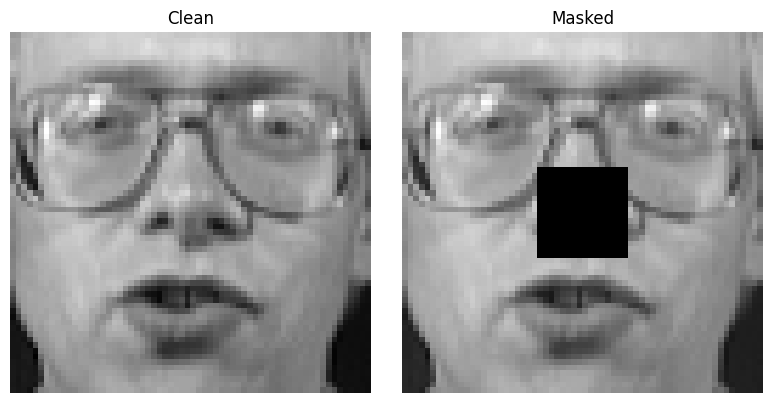

In [48]:
#clean and masked face
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test[face_idx].reshape(64, 64), cmap="gray")
plt.axis("off")
plt.title("Clean")

plt.subplot(1, 2, 2)
plt.imshow(X_test_occ[face_idx].reshape(64, 64), cmap="gray")
plt.axis("off")
plt.title("Masked")

plt.tight_layout()
plt.savefig("figures/bagging_vs_boosting_masked.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [49]:
#final boosting training distribution concentrated compared with uniform weighting
final_weights = weight_history[-1]

print("uniform weight:", 1 / len(X_train))
print("Final maximun weight:", final_weights.max())
print("Top 10 total weight:", np.sort(final_weights)[-10:].sum())

uniform weight: 0.004166666666666667
Final maximun weight: 0.06489055722527214
Top 10 total weight: 0.3688800594908291


In [50]:
top_idx = np.argsort(final_weights)[-10:][::-1]

for i in top_idx:
    print(
        "Index:", i,
        "Class:", y_train[i],
        "Weight:", final_weights[i]
    )

Index: 22 Class: 3 Weight: 0.06489055722527214
Index: 136 Class: 22 Weight: 0.060371128068205604
Index: 51 Class: 8 Weight: 0.042098715559726184
Index: 53 Class: 8 Weight: 0.042098715559726184
Index: 3 Class: 0 Weight: 0.03964518250906881
Index: 36 Class: 6 Weight: 0.031047790467238746
Index: 109 Class: 18 Weight: 0.02889894819153824
Index: 180 Class: 30 Weight: 0.019943007303351044
Index: 181 Class: 30 Weight: 0.019943007303351044
Index: 185 Class: 30 Weight: 0.019943007303351044


**Question 3: Bias and variance as measured quantities**

**Part (A)**

In [51]:
#create the 30 resampled training sets
rng_q3 = np.random.default_rng(260002)

resample_sets = []

for r in range(30):
    idx = []

    for person in range(40):
        p = np.where(y_train == person)[0]
        idx.extend(rng_q3.choice(p, 6, replace=True))

    resample_sets.append(idx)

resample_sets = np.array(resample_sets)

np.save("q3_resample_sets.npy", resample_sets)

print(resample_sets.shape)

(30, 240)


In [54]:
#class score vector calculation
#single tree
def tree_score_vector(tree, X):
    return tree.predict_proba(X)

#bagging
def bagging_score_vector(Xtr, ytr, Xte, B, rng):

    scores = np.zeros((len(Xte), 40))

    for b in range(B):

        idx = rng.choice(len(Xtr), len(Xtr), replace=True)

        tree = DecisionTreeClassifier(
            max_depth=None,
            min_samples_leaf=2,
            random_state=260002
        )

        tree.fit(Xtr[idx], ytr[idx])

        pred = tree.predict(Xte)

        for i, p in enumerate(pred):
            scores[i, p] += 1

    return scores / B


#boosting 
def boosting_score_vector(models, alphas, X):

    scores = np.zeros((len(X), 40))

    for tree, alpha in zip(models, alphas):

        pred = tree.predict(X)

        for i, p in enumerate(pred):
            scores[i, p] += alpha

    return scores / np.sum(alphas)

In [57]:
#runnning the 30 refits parallely 
from joblib import Parallel, delayed

def run_refit(r):

    idx = resample_sets[r]
    X_r = X_train[idx]
    y_r = y_train[idx]

    tree = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=2,
        random_state=260002
    )
    tree.fit(X_r, y_r)

    s_tree = tree_score_vector(tree, X_test)

    rng = np.random.default_rng(260002 + r)
    s_bag = bagging_score_vector(X_r, y_r, X_test, 200, rng)

    models, alphas, _, _, _ = train_samme(X_r, y_r, 4, 100)
    s_boost = boosting_score_vector(models, alphas, X_test)

    return (
        s_tree,
        s_bag,
        s_boost,
        np.mean(np.argmax(s_tree, axis=1) == y_test),
        np.mean(np.argmax(s_bag, axis=1) == y_test),
        np.mean(np.argmax(s_boost, axis=1) == y_test)
    )

In [58]:
results = Parallel(n_jobs=8, verbose=10)(
    delayed(run_refit)(r) for r in range(30)
)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed: 13.9min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed: 27.9min
[Parallel(n_jobs=8)]: Done  19 out of  30 | elapsed: 42.4min remaining: 24.6min
[Parallel(n_jobs=8)]: Done  23 out of  30 | elapsed: 43.1min remaining: 13.1min
[Parallel(n_jobs=8)]: Done  27 out of  30 | elapsed: 55.9min remaining:  6.2min
[Parallel(n_jobs=8)]: Done  30 out of  30 | elapsed: 56.3min finished


In [60]:
#collecting the results
tree_scores_all = np.array([x[0] for x in results])
bag_scores_all = np.array([x[1] for x in results])
boost_scores_all = np.array([x[2] for x in results])

tree_acc = np.array([x[3] for x in results])
bag_acc = np.array([x[4] for x in results])
boost_acc = np.array([x[5] for x in results])

print(tree_scores_all.shape)
print(bag_scores_all.shape)
print(boost_scores_all.shape)

(30, 80, 40)
(30, 80, 40)
(30, 80, 40)


In [61]:
np.savez(
    "q3_part_a_results.npz",
    tree_scores=tree_scores_all,
    bag_scores=bag_scores_all,
    boost_scores=boost_scores_all,
    tree_acc=tree_acc,
    bag_acc=bag_acc,
    boost_acc=boost_acc
)

In [63]:
#bias variance definition and calaculation
def bias_variance(scores, y):

    mean_scores = scores.mean(axis=0)
    target = np.eye(40)[y]

    bias2 = np.mean(np.sum((mean_scores - target) ** 2, axis=1))
    var = np.mean(np.sum((scores - mean_scores) ** 2, axis=2))

    return bias2, var


tree_bias, tree_var = bias_variance(tree_scores_all, y_test)
bag_bias, bag_var = bias_variance(bag_scores_all, y_test)
boost_bias, boost_var = bias_variance(boost_scores_all, y_test)
#each output line prints bias squared, variance, mean test accuracy and std test accuracy
print("Tree:", tree_bias, tree_var, tree_acc.mean(), tree_acc.std())
print("Bagging:", bag_bias, bag_var, bag_acc.mean(), bag_acc.std())
print("Boosting:", boost_bias, boost_var, boost_acc.mean(), boost_acc.std())

Tree: 0.40366666666666673 0.618 0.48916666666666675 0.05181430518903272
Bagging: 0.5238183666666666 0.020325383333333332 0.7466666666666667 0.050819670294964425
Boosting: 0.8853225060489981 0.017573058831535808 0.31125 0.08805478881544906


**Part (B)**

In [64]:
#defining bagging for a chosen depth

def bagging_depth(Xtr, ytr, Xte, depth, rng):

    scores = np.zeros((len(Xte), 40))
    preds = []

    for b in range(100):

        idx = rng.choice(len(Xtr), len(Xtr), replace=True)

        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=2,
            random_state=260002
        )

        tree.fit(Xtr[idx], ytr[idx])

        p = tree.predict(Xte)
        preds.append(p)

        for i, c in enumerate(p):
            scores[i, c] += 1

    return scores / 100, np.array(preds)

In [65]:
def disagreement(preds):

    values = []

    for i in range(len(preds)):
        for j in range(i + 1, len(preds)):
            values.append(np.mean(preds[i] != preds[j]))

    return np.mean(values)

In [66]:
def run_depth_refit(r, depth):

    idx = resample_sets[r]

    X_r = X_train[idx]
    y_r = y_train[idx]

    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=2,
        random_state=260002
    )

    tree.fit(X_r, y_r)

    s_tree = tree_score_vector(tree, X_test)

    leaf = tree.apply(X_r)
    _, counts = np.unique(leaf, return_counts=True)

    d = 99 if depth is None else depth
    rng = np.random.default_rng(260002 + r + d * 1000)

    s_bag, preds = bagging_depth(
        X_r, y_r, X_test, depth, rng
    )

    return (
        s_tree,
        s_bag,
        np.mean(np.argmax(s_tree, axis=1) == y_test),
        np.mean(np.argmax(s_bag, axis=1) == y_test),
        counts.mean(),
        disagreement(preds)
    )

In [67]:
depths = [4, 16, None]

depth_results = {}

for d in depths:

    print("Depth:", d)

    depth_results[d] = Parallel(n_jobs=8, verbose=10)(
        delayed(run_depth_refit)(r, d)
        for r in range(30)
    )

Depth: 4


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  1.3min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  2.7min
[Parallel(n_jobs=8)]: Done  19 out of  30 | elapsed:  4.0min remaining:  2.3min
[Parallel(n_jobs=8)]: Done  23 out of  30 | elapsed:  4.0min remaining:  1.2min
[Parallel(n_jobs=8)]: Done  27 out of  30 | elapsed:  5.2min remaining:   34.7s
[Parallel(n_jobs=8)]: Done  30 out of  30 | elapsed:  5.2min finished


Depth: 16


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  3.2min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  6.2min
[Parallel(n_jobs=8)]: Done  19 out of  30 | elapsed:  9.3min remaining:  5.4min
[Parallel(n_jobs=8)]: Done  23 out of  30 | elapsed:  9.3min remaining:  2.8min
[Parallel(n_jobs=8)]: Done  27 out of  30 | elapsed: 12.0min remaining:  1.3min
[Parallel(n_jobs=8)]: Done  30 out of  30 | elapsed: 12.1min finished


Depth: None


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  4.2min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  8.5min
[Parallel(n_jobs=8)]: Done  19 out of  30 | elapsed: 12.8min remaining:  7.4min
[Parallel(n_jobs=8)]: Done  23 out of  30 | elapsed: 13.0min remaining:  4.0min
[Parallel(n_jobs=8)]: Done  27 out of  30 | elapsed: 16.7min remaining:  1.9min
[Parallel(n_jobs=8)]: Done  30 out of  30 | elapsed: 16.8min finished


In [68]:
#summary of the obtained results
for d in depths:

    result = depth_results[d]

    tree_scores = np.array([x[0] for x in result])
    bag_scores = np.array([x[1] for x in result])

    tree_acc_d = np.array([x[2] for x in result])
    bag_acc_d = np.array([x[3] for x in result])

    leaf_occ = np.array([x[4] for x in result])
    dis = np.array([x[5] for x in result])

    tb, tv = bias_variance(tree_scores, y_test)
    bb, bv = bias_variance(bag_scores, y_test)

    print("\nDepth:", d)
    print("Tree bias/var:", tb, tv)
    print("Bag bias/var:", bb, bv)
    print("Tree acc:", tree_acc_d.mean())
    print("Bag acc:", bag_acc_d.mean())
    print("Variance removed:", tv - bv)
    print("Leaf occupancy:", leaf_occ.mean())
    print("Disagreement:", dis.mean())


Depth: 4
Tree bias/var: 0.8857874943444456 0.05258766127335708
Bag bias/var: 0.8912244583333333 0.013141125
Tree acc: 0.08458333333333333
Bag acc: 0.28875000000000006
Variance removed: 0.03944653627335708
Leaf occupancy: 47.46666666666667
Disagreement: 0.9466425084175084

Depth: 16
Tree bias/var: 0.6741512688148646 0.25225407930923344
Bag bias/var: 0.675157325 0.020658175
Tree acc: 0.25875
Bag acc: 0.6024999999999999
Variance removed: 0.23159590430923344
Leaf occupancy: 13.336635706914345
Disagreement: 0.8838816498316499

Depth: None
Tree bias/var: 0.40366666666666673 0.618
Bag bias/var: 0.5241961333333334 0.02379561666666667
Tree acc: 0.48916666666666675
Bag acc: 0.7383333333333333
Variance removed: 0.5942043833333334
Leaf occupancy: 5.995121951219512
Disagreement: 0.8158079966329966


In [69]:
#saving the results

part_b_summary = []

for d in depths:

    result = depth_results[d]

    tree_scores = np.array([x[0] for x in result])
    bag_scores = np.array([x[1] for x in result])

    tree_acc_d = np.array([x[2] for x in result])
    bag_acc_d = np.array([x[3] for x in result])

    leaf_occ = np.array([x[4] for x in result])
    dis = np.array([x[5] for x in result])

    tree_bias, tree_var = bias_variance(tree_scores, y_test)
    bag_bias, bag_var = bias_variance(bag_scores, y_test)

    part_b_summary.append([
        -1 if d is None else d,
        tree_bias,
        tree_var,
        tree_acc_d.mean(),
        bag_bias,
        bag_var,
        bag_acc_d.mean(),
        tree_var - bag_var,
        leaf_occ.mean(),
        dis.mean()
    ])

part_b_summary = np.array(part_b_summary)

np.save("q3_part_b_summary.npy", part_b_summary)

**Part (C)**

In [70]:
#calculating the accuracy improvement from bagging at each depth
for d in depths:

    result = depth_results[d]

    t = np.mean([x[2] for x in result])
    b = np.mean([x[3] for x in result])

    print(d, b - t)


4 0.20416666666666672
16 0.34374999999999994
None 0.24916666666666654


In [71]:
#the deepest tree is necessarily not where bagging gives the largest accuracy improvement

**Part (D)**

In [75]:
# summarising all the final selected model results

import pandas as pd

tree_bias_a, tree_var_a = bias_variance(tree_scores_all, y_test)
bag_bias_a, bag_var_a = bias_variance(bag_scores_all, y_test)
boost_bias_a, boost_var_a = bias_variance(boost_scores_all, y_test)

final_table = pd.DataFrame({
    "Model": ["Single Tree", "Bagging", "Boosting"],

    "Clean Test Accuracy": [
        np.mean(tree_clean_pred == y_test),
        np.mean(bag_clean_pred == y_test),
        np.mean(boost_clean_pred == y_test)
    ],

    "Masked Test Accuracy": [
        np.mean(tree_masked_pred == y_test),
        np.mean(bag_masked_pred == y_test),
        np.mean(boost_masked_pred == y_test)
    ],

    "Bias Squared": [
        tree_bias_a,
        bag_bias_a,
        boost_bias_a
    ],

    "Variance": [
        tree_var_a,
        bag_var_a,
        boost_var_a
    ]
})

print(final_table)

final_table.to_csv("q3_final_comparison.csv", index=False)

         Model  Clean Test Accuracy  Masked Test Accuracy  Bias Squared  \
0  Single Tree               0.6125                0.0750      0.403667   
1      Bagging               0.8250                0.7875      0.523818   
2     Boosting               0.4750                0.2750      0.885323   

   Variance  
0  0.618000  
1  0.020325  
2  0.017573  
